# Phase transitions in the Heisenberg model

In [1]:
using Pkg; Pkg.update()

using MX2RKKY.montecarlo
using MX2RKKY.lattice

using Random: MersenneTwister
using Statistics: mean, std

    Updating registry at `~/.julia/registries/General.toml`
    Updating git-repo `/home/igor/Physics/MX2-RKKY/MX2RKKY.git`
  No Changes to `~/Physics/MX2-RKKY/MX2RKKY.git/notebooks/Project.toml`
  No Changes to `~/Physics/MX2-RKKY/MX2RKKY.git/notebooks/Manifest.toml`


Function that performs temperature scans

In [2]:
function temperature_scan(L::Int, χ_init::Int, T_range::AbstractRange;
                          n_cycles::Int, n_warmup_cycles::Int, cycle_length::Int, seed::Int=123456)
    @assert mod(L, 3) == 0
    @assert χ_init ∈ (-1, 1)

    E = zeros(n_cycles, length(T_range))
    χ = zeros(n_cycles, length(T_range))

    rng = MersenneTwister(seed)
    conf = Configuration(L, L, χ_init)

    for (n, T) in enumerate(T_range)
        @show T
        sim = MCSimulation(conf, rng, β=1/T, Jpar=1.0, Jperp=.0, Vpar=.0, Vperp=.0, λ=.0, Vrenormalize=false)
        run!(sim, n_cycles=n_cycles, n_warmup_cycles=n_warmup_cycles, cycle_length=cycle_length, inplane=true, update_triangle_prob=0.1)
        @show acceptance_rates(sim)

        E[:, n] = sim.measurements.energy
        χ[:, n] = sim.measurements.chirality

        conf = deepcopy(sim.conf)
    end

    return E, χ
end

temperature_scan (generic function with 1 method)

A few temperature scans with various system sizes

In [3]:
T_range = 0.01:0.01:1.0

n_warmup_cycles = 50_000
n_cycles = 100_000
cycle_length = 50

for L in [24, 27, 30]
    E, χ = temperature_scan(24, -1, T_range; n_cycles=n_cycles, n_warmup_cycles=n_warmup_cycles, cycle_length=cycle_length)
    write("heisenberg_T_scan_L$(L)_E.dat", E)
    write("heisenberg_T_scan_L$(L)_chi.dat", χ)
end

T = 0.01


Running MC simulation 100%|██████████████████████████████| Time: 0:02:15m


acceptance_rates(sim) = Dict{DataType, Float64}(MX2RKKY.montecarlo.UpdateTriangle => 0.020835642099613194, MX2RKKY.montecarlo.UpdateSingleSpin{true} => 0.029409974132885836)
T = 0.02


Running MC simulation 100%|██████████████████████████████| Time: 0:02:14


acceptance_rates(sim) = Dict{DataType, Float64}(MX2RKKY.montecarlo.UpdateTriangle => 0.029478929624104654, MX2RKKY.montecarlo.UpdateSingleSpin{true} => 0.04168909302118515)
T = 0.03


Running MC simulation 100%|██████████████████████████████| Time: 0:02:14


... (229 outputs left out)

Running MC simulation 100%|██████████████████████████████| Time: 0:02:25


acceptance_rates(sim) = Dict{DataType, Float64}(MX2RKKY.montecarlo.UpdateTriangle => 0.09086166130263292, MX2RKKY.montecarlo.UpdateSingleSpin{true} => 0.1293331934931659)
T = 0.19


Running MC simulation  20%|██████▏                       |  ETA: 0:01:22

LoadError: InterruptException:

In [4]:
using PyPlot; const plt = PyPlot;

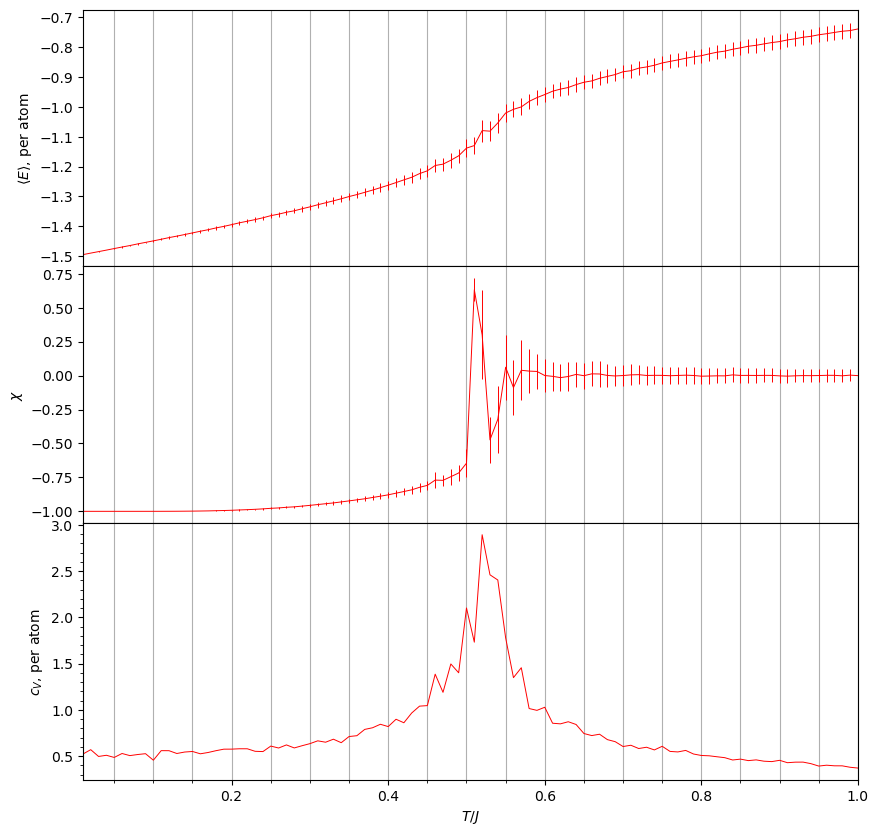

In [17]:
L1 = L2 = 24
E = zeros(n_cycles, length(T_range))
χ = zeros(n_cycles, length(T_range))
read!("heisenberg_T_scan_L$(L1)_E.dat", E)
read!("heisenberg_T_scan_L$(L1)_chi.dat", χ)

E_avg = [mean(E[:, n]) for n in 1:length(T_range)]
E_var = [std(E[:, n]) for n in 1:length(T_range)]

χ_avg = [mean(χ[:, n]) for n in 1:length(T_range)]
χ_var = [std(χ[:, n]) for n in 1:length(T_range)]

E2_avg = [mean(E[:, n] .^ 2) for n in 1:length(T_range)]
cV = (E2_avg - (E_avg .^ 2)) ./ (collect(T_range) .^ 2)

plt.figure(figsize=(10,10))
gs = plt.matplotlib.gridspec.GridSpec(3, 1, hspace=0)

ax1 = plt.subplot(gs[1])
ax1.errorbar(collect(T_range), E_avg / (L1 * L2), yerr=E_var / (L1 * L2), lw=0.7, color="red")
ax1.set_ylabel(raw"$\langle E\rangle$, per atom")
plt.setp(ax1.get_xticklabels(), visible=false)
ax1.grid(axis="x", which="both")

ax2 = plt.subplot(gs[2], sharex=ax1)
ax2.errorbar(collect(T_range), χ_avg, yerr=χ_var, lw=0.7, color="red")
ax2.set_ylabel(raw"$\chi$")
plt.setp(ax2.get_xticklabels(), visible=false)
ax2.grid(axis="x", which="both")

ax3 = plt.subplot(gs[3], sharex=ax1)
ax3.plot(collect(T_range), cV / (L1 * L2), lw=0.7, color="red")
ax3.set_ylabel(raw"$c_V$, per atom")
ax3.grid(axis="x", which="both")

ax3.set_xlim((first(T_range), last(T_range)))
ax3.set_xlabel(raw"$T/J$")
ax3.minorticks_on()
plt.show()